**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: ENMANUEL ABREU
*   MATRÍCULA: A01841472

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [ ]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Cargar el archivo CSV desde la ruta correspondiente en Google Drive
loan_df = pd.read_csv('/content/drive/MyDrive/Ciencia de Datos/Semana 4/personal_loan.csv')

# Utilizar ID como índice del dataframe
loan_df.set_index('ID', inplace=True)

# Mostrar el resumen de las columnas y sus tipos de datos
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


**Respuesta:** Hay **8** columnas numéricas y **5** columnas de texto u objetos.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [ ]:
# Mostrar las estadísticas de las columnas numéricas
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


In [ ]:
# Filtrar los clientes con edades mayores de 100 años
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [ ]:
# Eliminar los registros con edades mayores de 100 años
loan_df = loan_df[loan_df['Age'] <= 100]

In [ ]:
# Cargar el archivo original para contar correctamente
loan_df = pd.read_csv('/content/drive/MyDrive/Ciencia de Datos/Semana 4/personal_loan.csv')
loan_df.set_index('ID', inplace=True)

# Guardado del total inicial de registros
total_inicial = len(loan_df)

# Revisión los registros con edades mayores de 100 años
print("Edades mayores de 100:")
print(loan_df[loan_df['Age'] > 100][['Age']])

# Identificación de registros que tienen valores inválidos
invalidos = (
    (loan_df['Age'] > 100) |
    (loan_df['Experience'] < 0) |
    (loan_df['Family'] < 0) |
    (~loan_df['Education'].isin([1, 2, 3]))
)

# Conteo de registros inválidos
registros_eliminados = invalidos.sum()

# Eliminación de registros inválidos
loan_df = loan_df[~invalidos].copy()

# Calculo del porcentaje eliminado respecto al total inicial
porcentaje_eliminado = (registros_eliminados / total_inicial) * 100

# Muestra de los resultados de la limpieza
print("Registros iniciales:", total_inicial)
print("Registros eliminados:", registros_eliminados)
print("Registros restantes:", len(loan_df))
print("Porcentaje eliminado:", round(porcentaje_eliminado, 2), "%")

Edades mayores de 100:
      Age
ID       
10    123
250   144
4800  130
Registros iniciales: 5037
Registros eliminados: 59
Registros restantes: 4978
Porcentaje eliminado: 1.17 %


**Justificación:**

**Experience y Family**

Valores negativos

*   No es posible tener una cantidad negativa de años de experiencia laboral.
*   El número de miembros de una familia no puede ser negativo.

**Education**

Valor **7.3**

*   Los únicos niveles válidos son 1, 2 y 3, según la descripción del conjunto de datos.

Aplicando los criterios anteriores, se identifican **59** registros únicos con al menos un valor inválido, lo que representa aproximadamente **1.17%** del dataframe inicial. Este valor se obtiene a partir de: (59/5037​)×100 = 1.17

 **Conclusión:** Se eliminan 59 registros porque contienen edades no plausibles, experiencia laboral negativa, tamaños familiares negativos o niveles educativos fuera de las categorías permitidas.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [ ]:
# Identificación de las columnas de texto
columnas_texto = loan_df.select_dtypes(include='object').columns

# Impresión de las frecuencias de las categorías de cada columna
for columna in columnas_texto:
    print(f"\nFrecuencias de {columna}:")
    print(loan_df[columna].value_counts(dropna=False))


Frecuencias de Personal Loan:
Personal Loan
0      3475
No     1018
Yes     368
1       117
Name: count, dtype: int64

Frecuencias de Securities Account:
Securities Account
No     2693
0      1766
Yes     390
1       129
Name: count, dtype: int64

Frecuencias de CD Account:
CD Account
No     2462
0      2213
1       163
Yes     140
Name: count, dtype: int64

Frecuencias de Online:
Online
Yes    1700
No     1628
1      1276
0       374
Name: count, dtype: int64

Frecuencias de CreditCard:
CreditCard
0      2628
Yes     908
No      885
1       557
Name: count, dtype: int64


In [ ]:
# Para estandarizar las variables binarias hay que convertir las respuestas a valores numéricos
columnas_binarias = [
    'Personal Loan',
    'Securities Account',
    'CD Account',
    'Online',
    'CreditCard'
]

for columna in columnas_binarias:
    loan_df[columna] = (
        loan_df[columna]
        .replace({
            'Yes': 1,
            'No': 0,
            '1': 1,
            '0': 0
        })
        .infer_objects(copy=False)
        .astype(int)
    )

# Comprobación de los tipos de datos después de unificar los valores
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4978 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 4978 non-null   int64  
 1   Experience          4978 non-null   int64  
 2   Income              4978 non-null   int64  
 3   ZIP Code            4978 non-null   int64  
 4   Family              4978 non-null   int64  
 5   CCAvg               4978 non-null   float64
 6   Education           4978 non-null   float64
 7   Mortgage            4978 non-null   int64  
 8   Personal Loan       4978 non-null   int64  
 9   Securities Account  4978 non-null   int64  
 10  CD Account          4978 non-null   int64  
 11  Online              4978 non-null   int64  
 12  CreditCard          4978 non-null   int64  
dtypes: float64(2), int64(11)
memory usage: 544.5 KB


4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [ ]:
# Conteo de registros duplicados
duplicados = loan_df.duplicated().sum()

print("Cantidad de registros duplicados:", duplicados)

Cantidad de registros duplicados: 36


Hay **36** registros duplicados.

In [ ]:
# Eliminación de registros duplicados
loan_df = loan_df.drop_duplicates()

# Reinicio del índice para mantener una secuencia continua
loan_df = loan_df.reset_index(drop=True)

# Comprobación del resultado
print("Registros finales:", len(loan_df))
print("Duplicados restantes:", loan_df.duplicated().sum())

# Muestra de los primeros registros
loan_df.head()

Registros finales: 4942
Duplicados restantes: 0


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91108,4,1.6,1.0,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1.0,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2.0,0,0,0,0,0,1


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [ ]:
# Convertir las variables a los tipos correspondientes

# ZIP Code
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype('object')

# Education
loan_df['Education'] = pd.Categorical(
    loan_df['Education'],
    categories=[1, 2, 3],
    ordered=True
)

# Binarias
columnas_binarias = [
    'Personal Loan',
    'Securities Account',
    'CD Account',
    'Online',
    'CreditCard'
]

for columna in columnas_binarias:
    loan_df[columna] = loan_df[columna].astype('category')

# Comprobación de los tipos de datos
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4942 entries, 0 to 4941
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Age                 4942 non-null   int64   
 1   Experience          4942 non-null   int64   
 2   Income              4942 non-null   int64   
 3   ZIP Code            4942 non-null   object  
 4   Family              4942 non-null   int64   
 5   CCAvg               4942 non-null   float64 
 6   Education           4942 non-null   category
 7   Mortgage            4942 non-null   int64   
 8   Personal Loan       4942 non-null   category
 9   Securities Account  4942 non-null   category
 10  CD Account          4942 non-null   category
 11  Online              4942 non-null   category
 12  CreditCard          4942 non-null   category
dtypes: category(6), float64(1), int64(5), object(1)
memory usage: 300.1+ KB


In [ ]:
# Lista de variables numéricas
num_cols = loan_df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Lista de variables categóricas y nominales
cat_cols = loan_df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Muestra de las listas
print("Variables numéricas:", num_cols)
print("\nVariables categóricas:", cat_cols)

Variables numéricas: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']

Variables categóricas: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


In [ ]:
# Comprobación de variables en cada grupo
print("Cantidad de variables numéricas:", len(num_cols))
print("Cantidad de variables categóricas:", len(cat_cols))

# Revisión de los tipos de datos finales
print(loan_df.dtypes)

Cantidad de variables numéricas: 6
Cantidad de variables categóricas: 7
Age                      int64
Experience               int64
Income                   int64
ZIP Code                object
Family                   int64
CCAvg                  float64
Education             category
Mortgage                 int64
Personal Loan         category
Securities Account    category
CD Account            category
Online                category
CreditCard            category
dtype: object


*   **Variables numéricas:** 6
*   **Variables categóricas:** 7


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [ ]:
# Obtener las estadísticas descriptivas de las variables numéricas
loan_df[num_cols].describe()

,Age,Experience,Income,Family,CCAvg,Mortgage
count,4942.000000,4942.000000,4942.000000,4942.000000,4942.000000,4942.000000
mean,45.561311,20.336301,73.815864,2.391947,1.935585,56.652165
std,11.314736,11.307402,46.108226,1.148356,1.748332,101.868229
min,24.000000,0.000000,8.000000,1.000000,0.000000,0.000000
25%,36.000000,11.000000,39.000000,1.000000,0.700000,0.000000
50%,46.000000,20.000000,64.000000,2.000000,1.500000,0.000000
75%,55.000000,30.000000,98.000000,3.000000,2.600000,101.000000
max,67.000000,43.000000,224.000000,4.000000,10.000000,635.000000


In [ ]:
# Calcular la asimetría y la curtosis de cada variable numérica
estadisticas = loan_df[num_cols].describe().T

estadisticas['skewness'] = loan_df[num_cols].skew()
estadisticas['kurtosis'] = loan_df[num_cols].kurtosis()

# Mostrar las estadísticas incluyendo asimetría y curtosis
estadisticas

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Age,4942.0,45.561311,11.314736,24.0,36.0,46.0,55.0,67.0,-0.023024,-1.161379
Experience,4942.0,20.336301,11.307402,0.0,11.0,20.0,30.0,43.0,-0.015453,-1.134596
Income,4942.0,73.815864,46.108226,8.0,39.0,64.0,98.0,224.0,0.842132,-0.046006
Family,4942.0,2.391947,1.148356,1.0,1.0,2.0,3.0,4.0,0.159089,-1.404189
CCAvg,4942.0,1.935585,1.748332,0.0,0.7,1.5,2.6,10.0,1.594922,2.636409
Mortgage,4942.0,56.652165,101.868229,0.0,0.0,0.0,101.0,635.0,2.104183,4.761586


In [ ]:
# Analizar las tres variables solicitadas
columnas = ['Age', 'Income', 'Mortgage']

for columna in columnas:
    asimetria = loan_df[columna].skew()
    curtosis = loan_df[columna].kurtosis()

    print(f"\nVariable: {columna}")
    print(f"Asimetría: {asimetria:.3f}")
    print(f"Curtosis: {curtosis:.3f}")

    # Clasificar la asimetría
    if asimetria > 0.5:
        print("Asimetría positiva")
    elif asimetria < -0.5:
        print("Asimetría negativa")
    else:
        print("Distribución relativamente simétrica")

    # Clasificar la curtosis
    if curtosis > 0.5:
        print("Leptocúrtica")
    elif curtosis < -0.5:
        print("Platicúrtica")
    else:
        print("Mesocúrtica o cercana a la normal")


Variable: Age
Asimetría: -0.023
Curtosis: -1.161
Distribución relativamente simétrica
Platicúrtica

Variable: Income
Asimetría: 0.842
Curtosis: -0.046
Asimetría positiva
Mesocúrtica o cercana a la normal

Variable: Mortgage
Asimetría: 2.104
Curtosis: 4.762
Asimetría positiva
Leptocúrtica


*   **Age:** presenta una distribución relativamente simétrica, con una curtosis negativa. Esto indica una distribución más aplanada que la normal.
*   **Income:** presenta asimetría positiva moderada; la mayoría de los ingresos se concentra en valores relativamente bajos o intermedios, con una cola hacia ingresos más elevados. Su curtosis está muy cerca de cero.
*   **Mortgage:** presenta una asimetría positiva pronunciada y curtosis elevada. Esto se relaciona con muchos clientes sin hipoteca o con montos bajos, junto con algunos clientes que poseen hipotecas considerablemente mayores.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

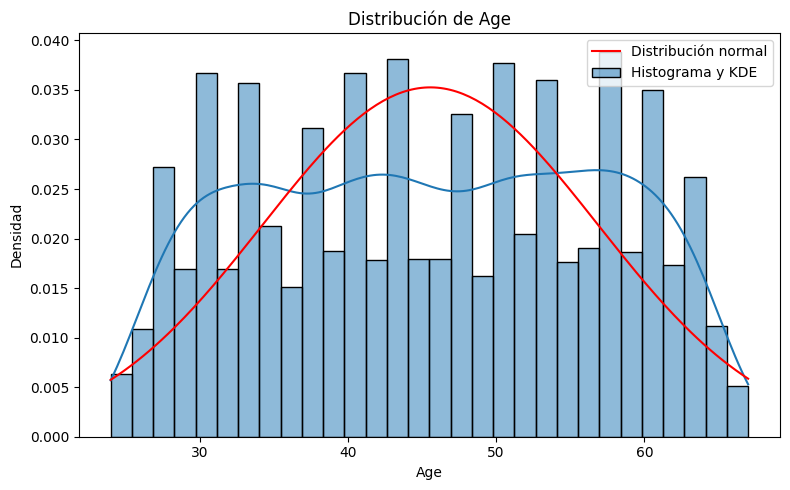

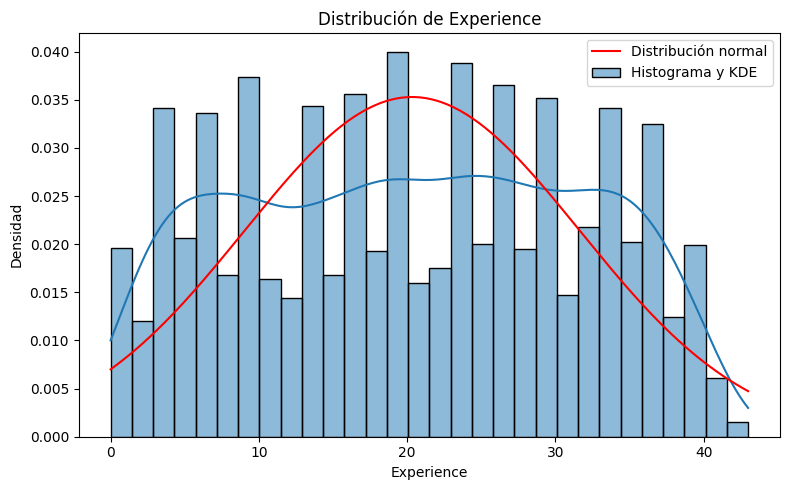

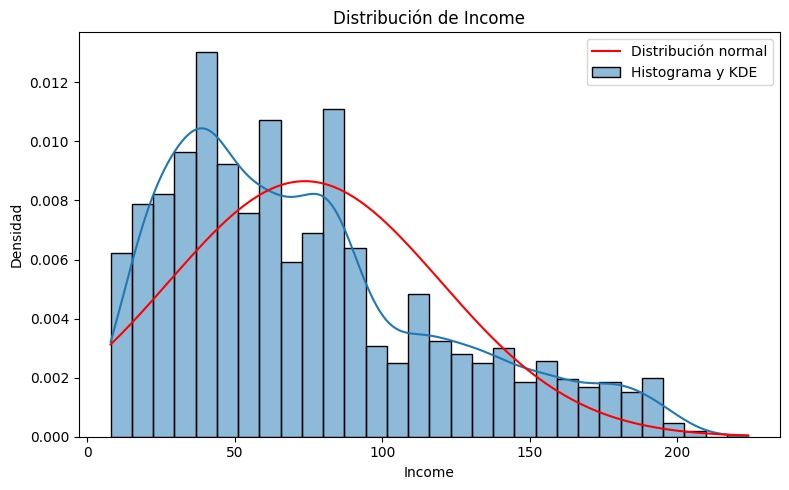

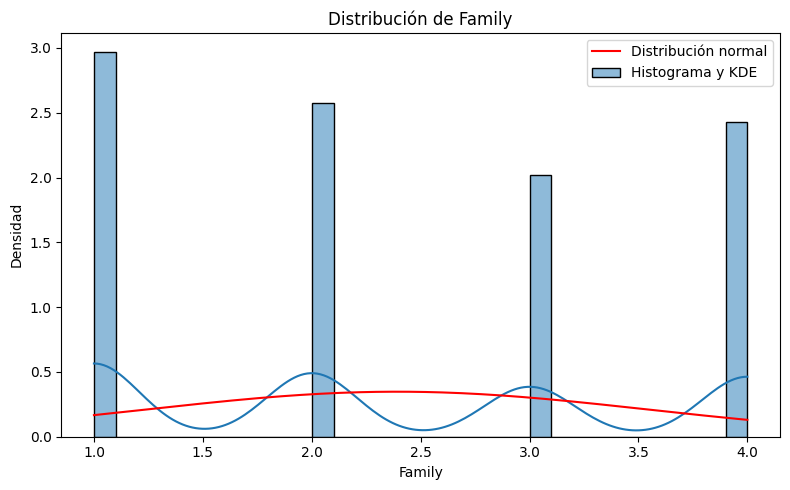

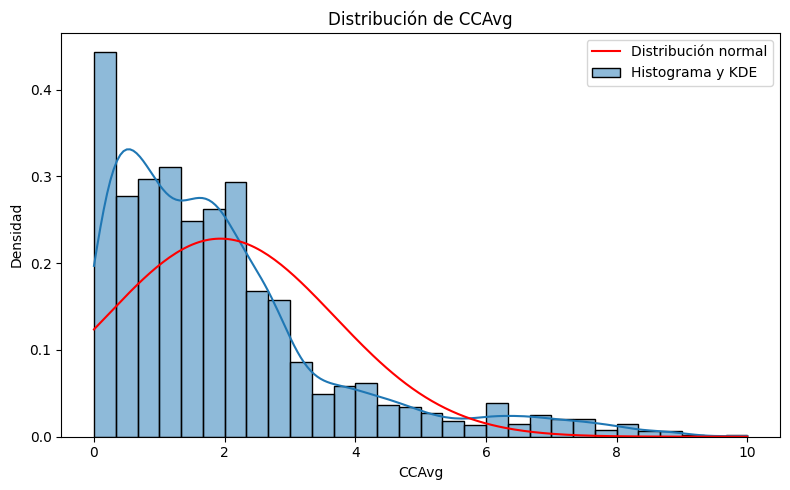

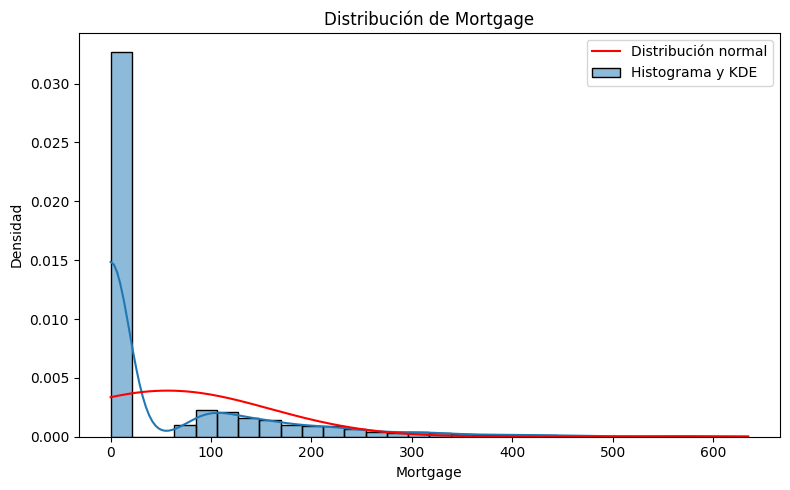

In [ ]:
# Generar un histograma para cada variable numérica

for columna in num_cols:
    datos = loan_df[columna].dropna()

    # Creación del histograma y la curva KDE
    plt.figure(figsize=(8, 5))
    sns.histplot(datos, stat='density', kde=True, bins=30,
                 label='Histograma y KDE')

    # Calcular la curva normal usando la media y desviación estándar
    x = np.linspace(datos.min(), datos.max(), 200)
    media = datos.mean()
    desviacion = datos.std()

    if desviacion > 0:
        plt.plot(
            x,
            norm.pdf(x, loc=media, scale=desviacion),
            label='Distribución normal',
            color='red'
        )

    plt.title(f'Distribución de {columna}')
    plt.xlabel(columna)
    plt.ylabel('Densidad')
    plt.legend()
    plt.tight_layout()
    plt.show()

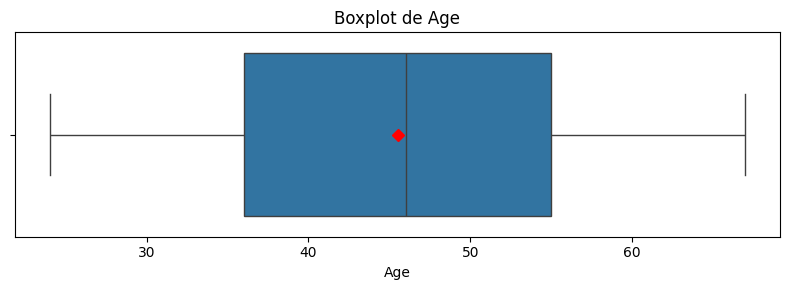

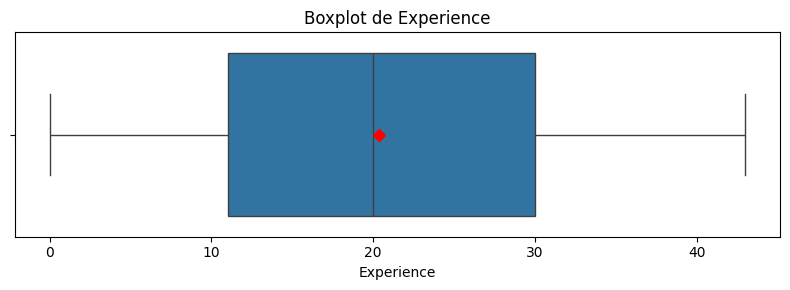

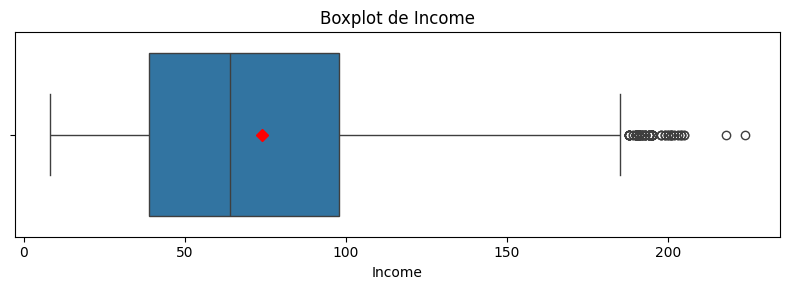

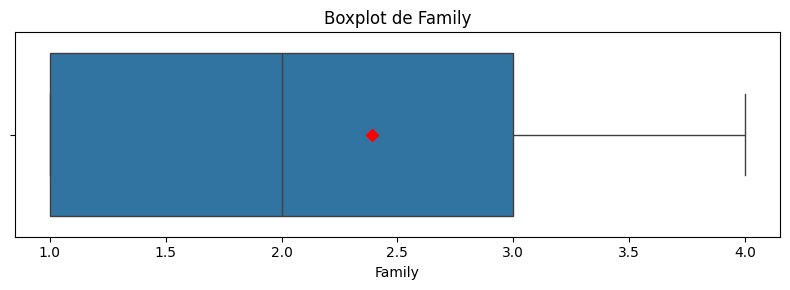

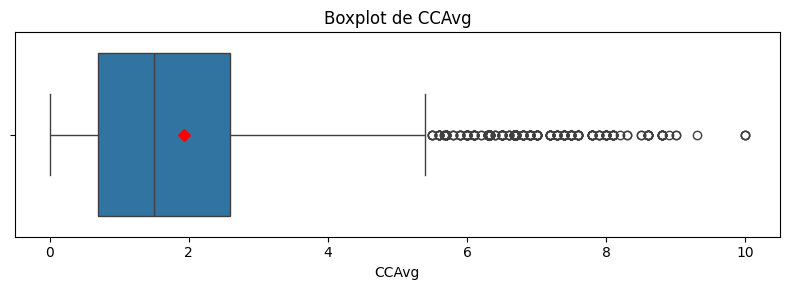

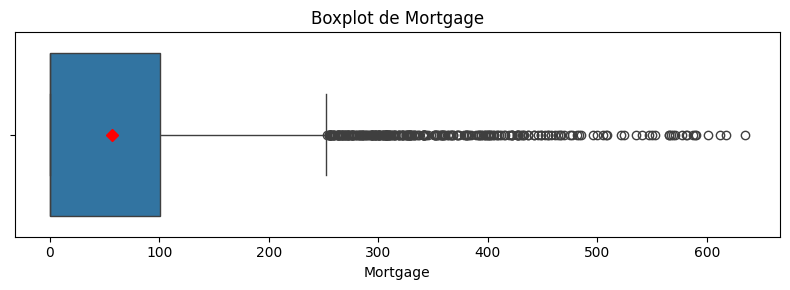

In [ ]:
# Crear un boxplot individual para cada variable numérica, incluyendo la media
for columna in num_cols:
    plt.figure(figsize=(8, 3))

    sns.boxplot(
        x=loan_df[columna],
        showmeans=True,
        meanprops={
            'marker': 'D',
            'markerfacecolor': 'red',
            'markeredgecolor': 'red'
        }
    )

    plt.title(f'Boxplot de {columna}')
    plt.xlabel(columna)
    plt.tight_layout()
    plt.show()

In [ ]:
# Comparación de la media y la mediana de las variables numéricas
comparacion = loan_df[num_cols].agg(['mean', 'median']).T

# Agregamos la asimetría para facilitar la interpretación
comparacion['asimetria'] = loan_df[num_cols].skew()

print(comparacion.round(3))

              mean  median  asimetria
Age         45.561    46.0     -0.023
Experience  20.336    20.0     -0.015
Income      73.816    64.0      0.842
Family       2.392     2.0      0.159
CCAvg        1.936     1.5      1.595
Mortgage    56.652     0.0      2.104


La relación entre la media y la mediana ayuda a interpretar el sesgo:

*   Media mayor que mediana: suele indicar asimetría positiva, con una cola hacia los valores altos.
*   Media menor que mediana: suele indicar asimetría negativa, con una cola hacia los valores bajos.
*   Media y mediana similares: sugieren una distribución aproximadamente simétrica, aunque conviene confirmar con el histograma.

**En conclusión:** La posición relativa de la media y la mediana **coincide** con los valores de asimetría calculados para las tres variables. Los histogramas permiten observar visualmente este comportamiento, mientras que los boxplots ayudan a identificar la dispersión y los posibles valores atípicos.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [ ]:
# Obtener las estadísticas descriptivas de las variables categóricas
loan_df[cat_cols].describe().T

,count,unique,top,freq
ZIP Code,4942,468,94720,163
Education,4942,3,1,2079
Personal Loan,4942,2,0,4463
Securities Account,4942,2,0,4427
CD Account,4942,2,0,4641
Online,4942,2,1,2952
CreditCard,4942,2,0,3489


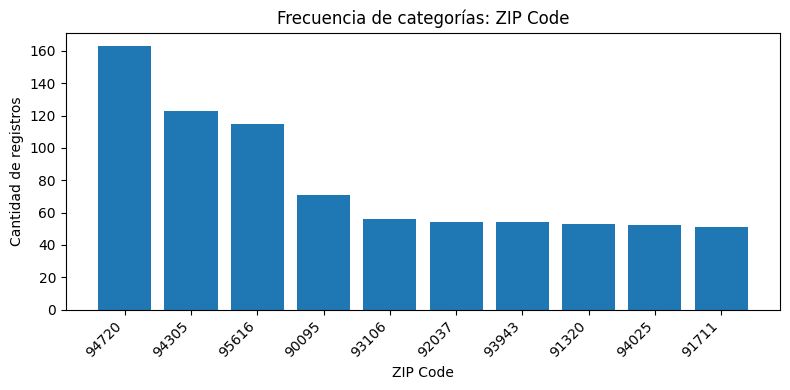

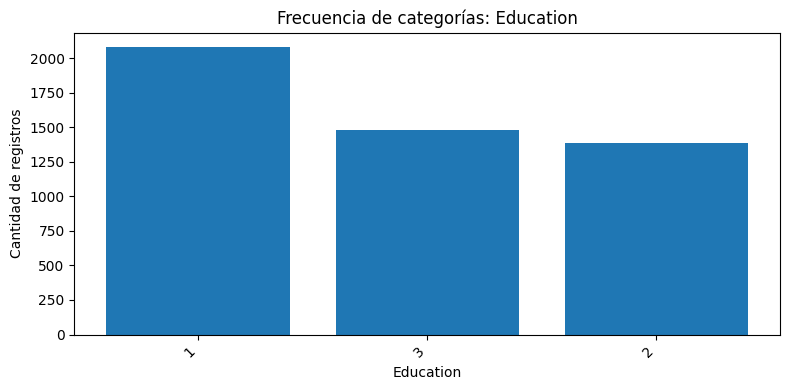

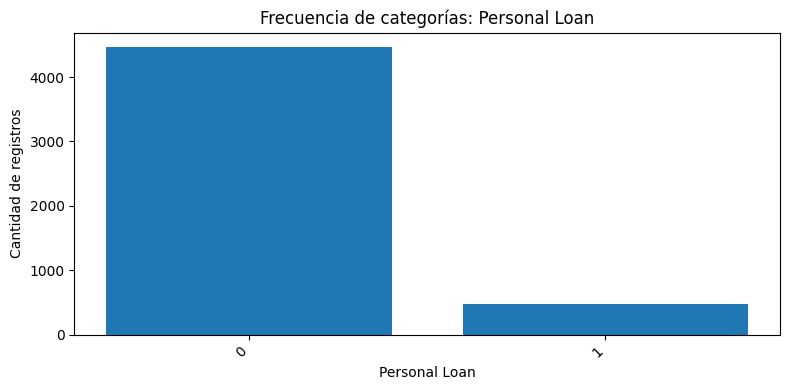

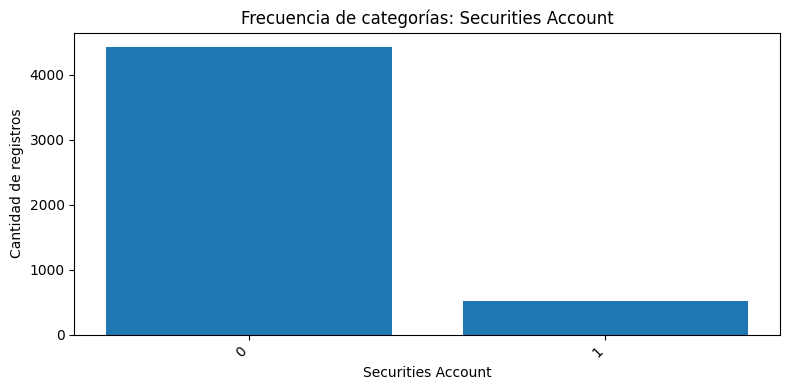

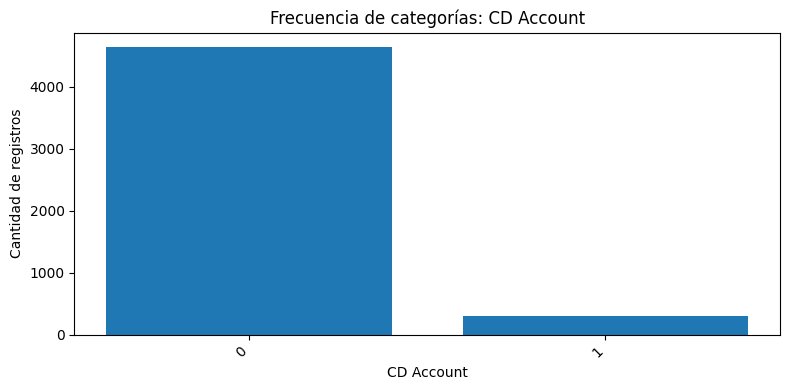

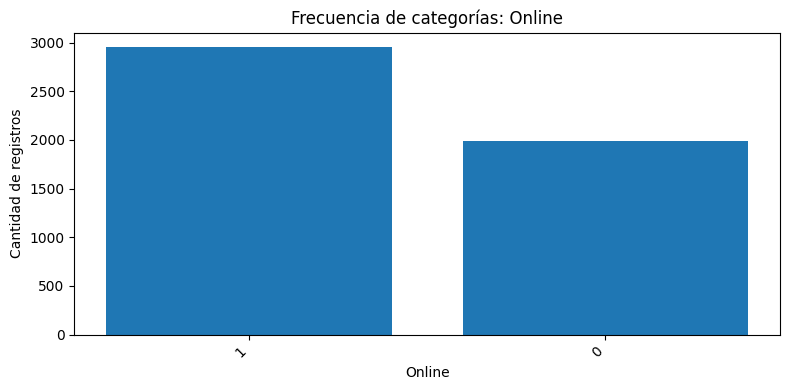

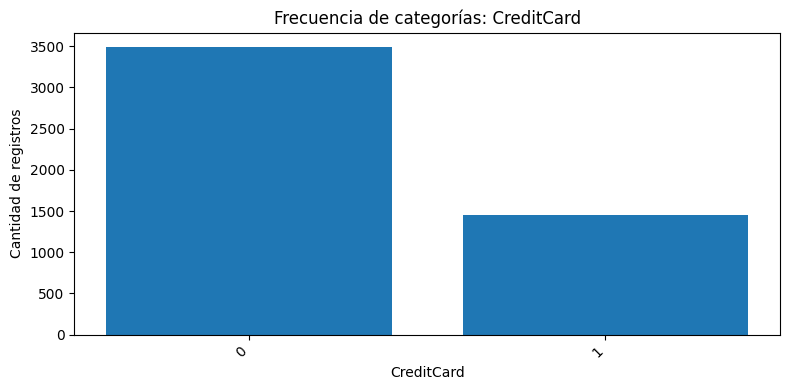

In [ ]:
# Generar un gráfico de barras para cada variable categórica
for columna in cat_cols:

    # Contar las categorías más frecuentes, incluyendo valores faltantes
    frecuencias = loan_df[columna].value_counts(dropna=False)

    # Si hay más de 10 categorías, mostrar solamente las 10 más frecuentes
    if len(frecuencias) > 10:
        frecuencias = frecuencias.head(10)

    # Crear el gráfico de barras
    plt.figure(figsize=(8, 4))
    plt.bar(frecuencias.index.astype(str), frecuencias.values)

    plt.title(f'Frecuencia de categorías: {columna}')
    plt.xlabel(columna)
    plt.ylabel('Cantidad de registros')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

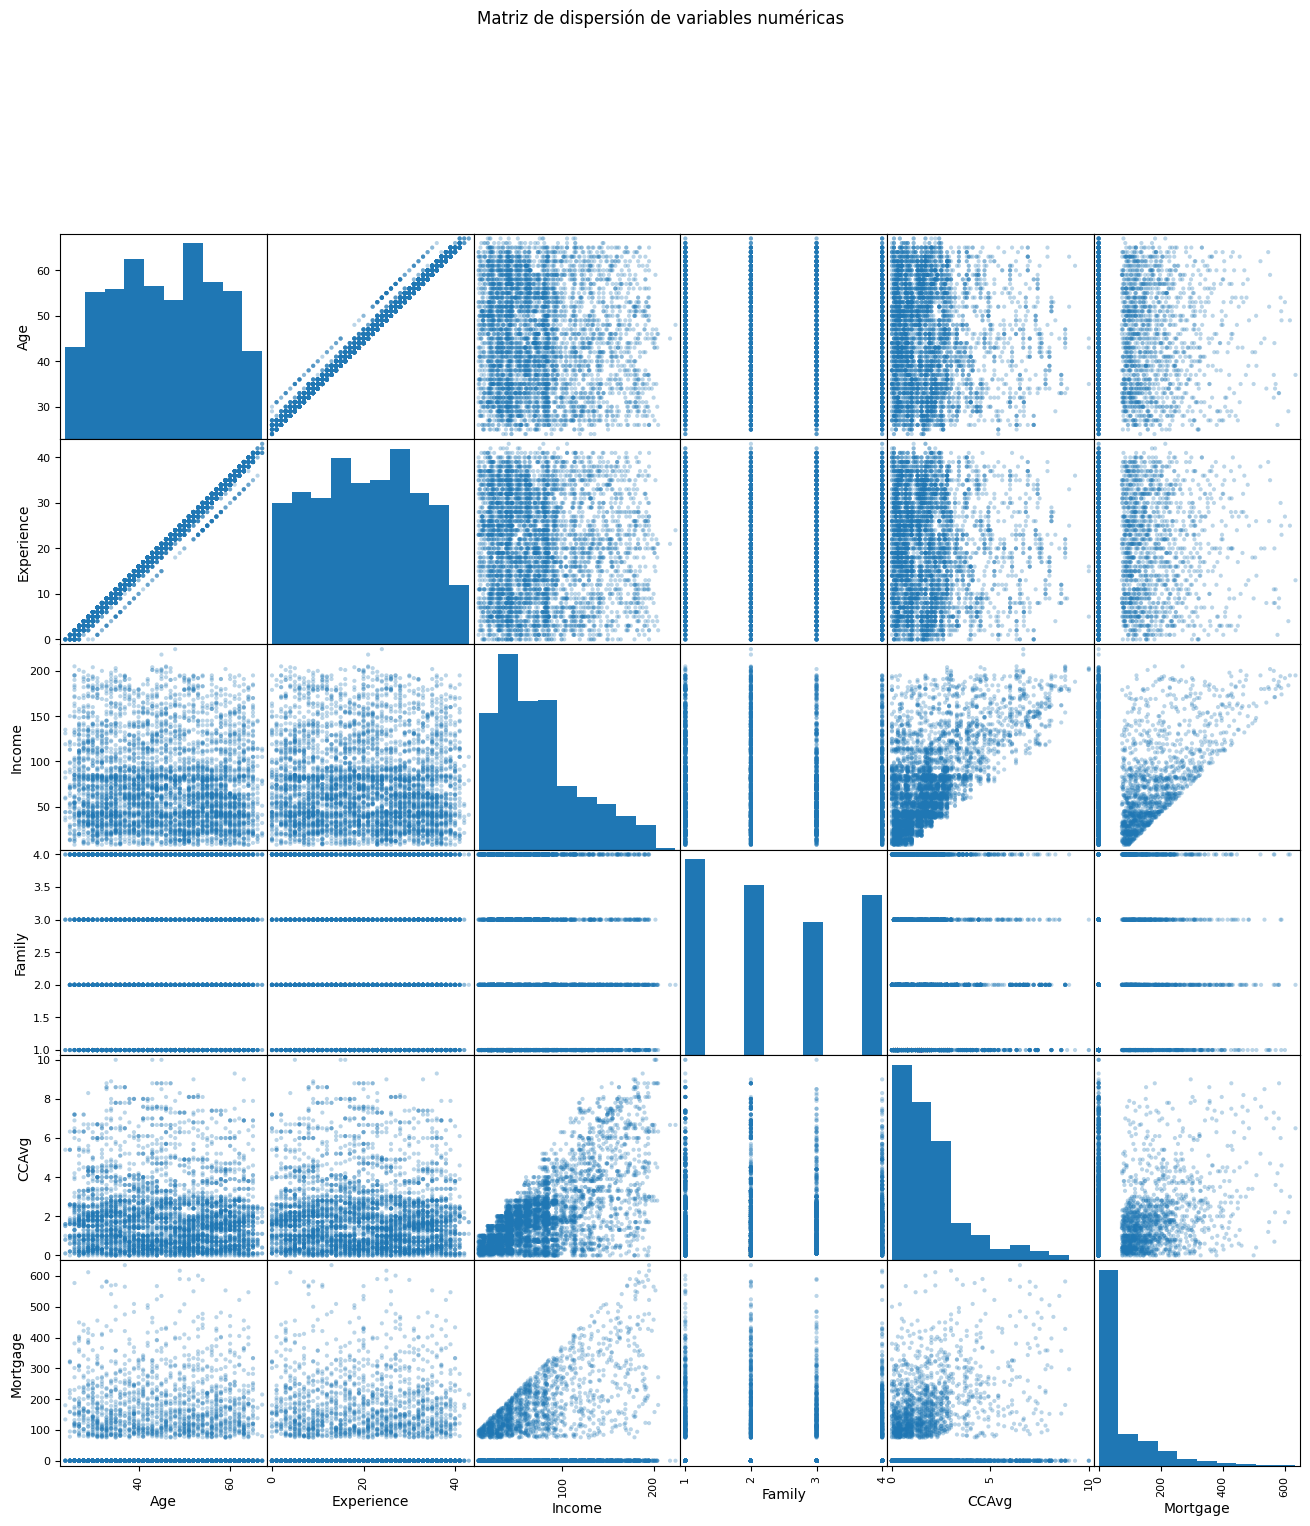

In [ ]:
# Generar la matriz de dispersión de las variables numéricas
pd.plotting.scatter_matrix(
    loan_df[num_cols],
    figsize=(16, 16),
    diagonal='hist',
    alpha=0.3
)

plt.suptitle('Matriz de dispersión de variables numéricas', y=1.02)
plt.show()

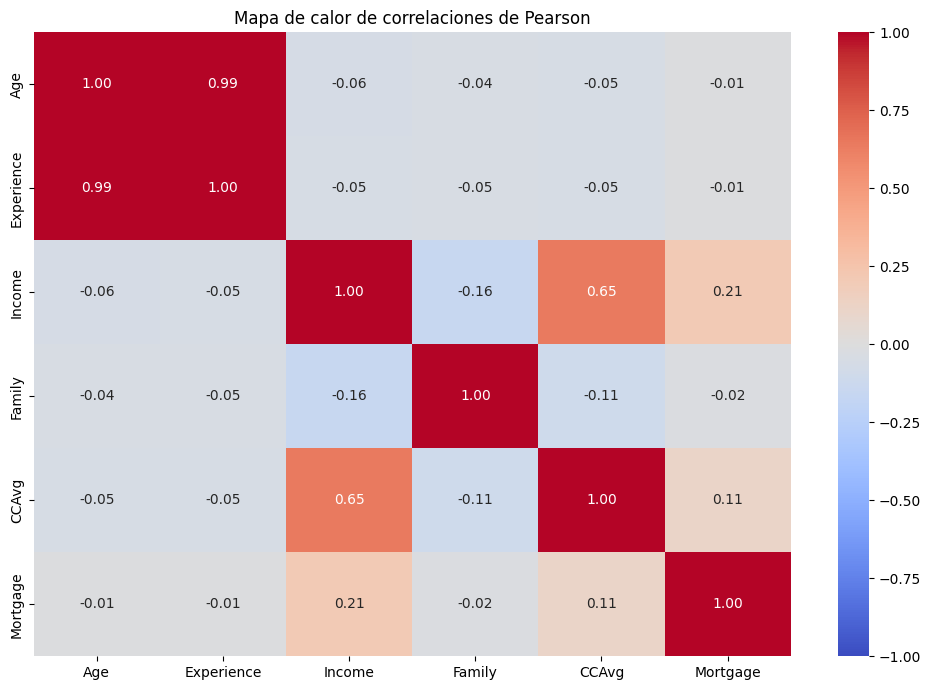

In [ ]:
# Calcular la matriz de correlación de Pearson
correlacion = loan_df[num_cols].corr(method='pearson')

# Representar las correlaciones con un mapa de calor
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlacion,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Mapa de calor de correlaciones de Pearson')
plt.tight_layout()
plt.show()

Correlación entre Income y CCAvg: 0.646


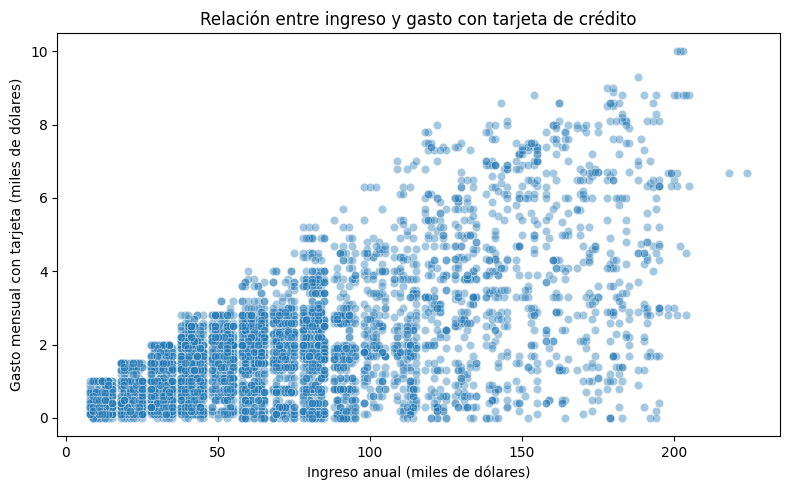

In [ ]:
# Calcular la correlación entre ingreso y gasto mensual con tarjeta
correlacion_par = loan_df['Income'].corr(loan_df['CCAvg'])

print(
    "Correlación entre Income y CCAvg:",
    round(correlacion_par, 3)
)

# Graficar la relación entre ambas variables
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=loan_df,
    x='Income',
    y='CCAvg',
    alpha=0.4
)

plt.title('Relación entre ingreso y gasto con tarjeta de crédito')
plt.xlabel('Ingreso anual (miles de dólares)')
plt.ylabel('Gasto mensual con tarjeta (miles de dólares)')
plt.tight_layout()
plt.show()

Al analizar el par Income y CCAvg, la correlación de Pearson es aproximadamente **0.646**, lo que indica una relación lineal positiva moderadamente fuerte.

**¿Qué indica esta correlación?** El valor indica que cuando el ingreso aumenta, el gasto con tarjeta tiende a aumentar también.

**¿El valor numérico coincide con lo esperado?** Sí. Una correlación positiva de esta magnitud es coherente con una nube de puntos que presenta una tendencia ascendente, aunque existe variabilidad entre los clientes.

**Conclusión:** La matriz de dispersión permite identificar visualmente posibles relaciones, mientras que el mapa de calor y el coeficiente de Pearson permiten cuantificar su dirección e intensidad. Ambos métodos se complementan para comprender mejor el comportamiento de los clientes bancarios.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


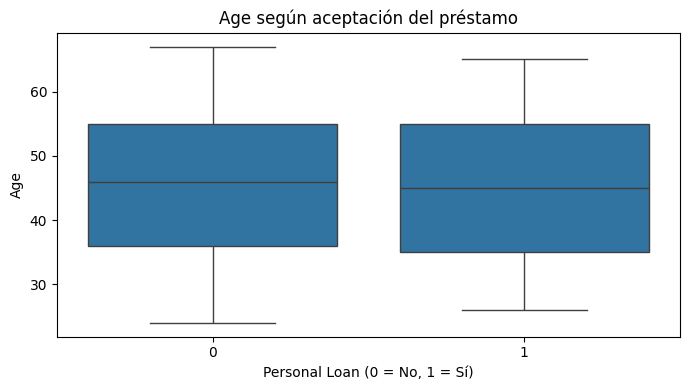

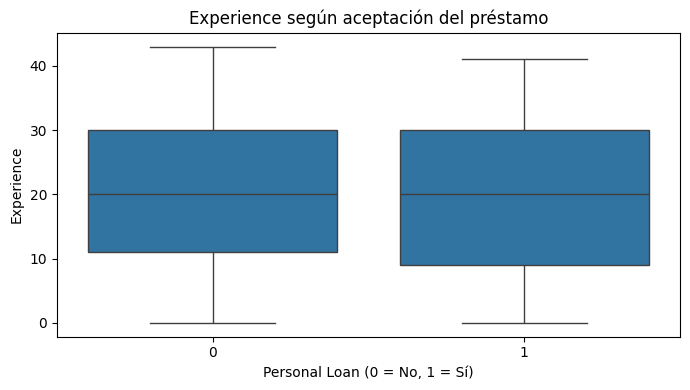

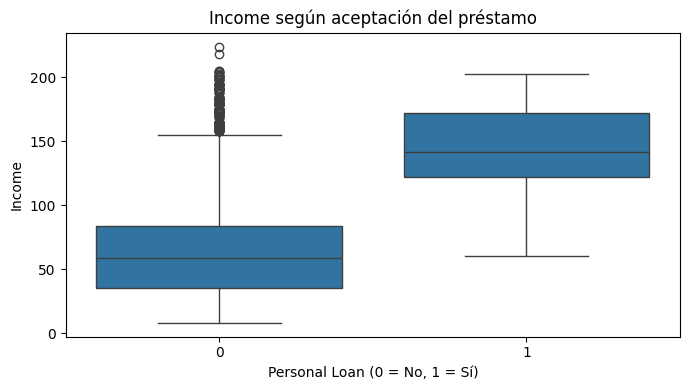

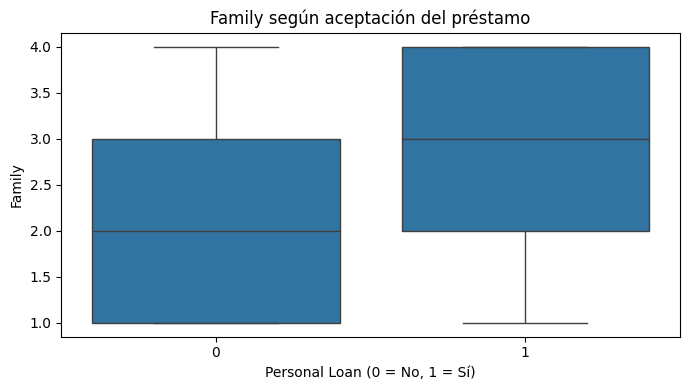

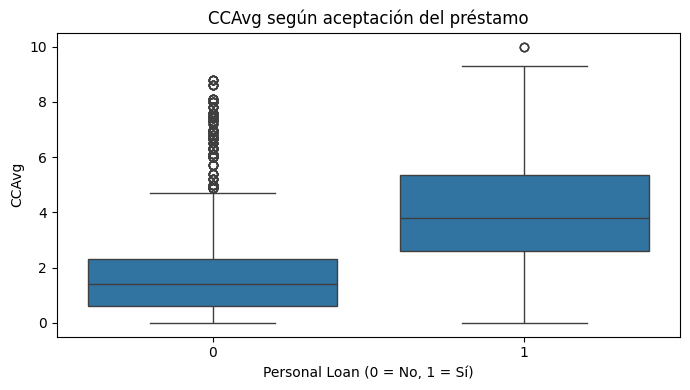

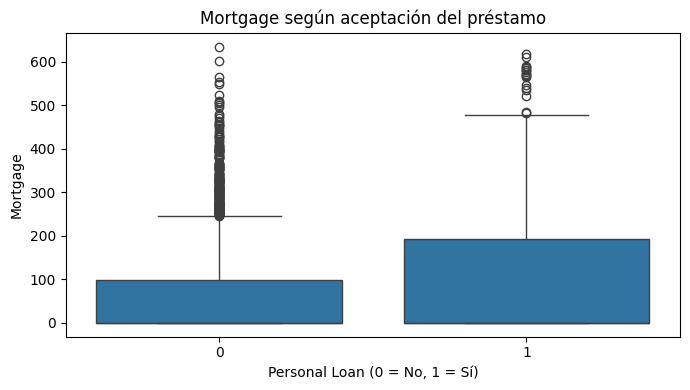

In [ ]:
# Excluir la variable de salida de las variables numéricas
num_cols_loan = [
    columna for columna in num_cols
    if columna != 'Personal Loan'
]

# Crear un boxplot para cada variable numérica
for columna in num_cols_loan:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=loan_df,
        x='Personal Loan',
        y=columna
    )

    plt.title(f'{columna} según aceptación del préstamo')
    plt.xlabel('Personal Loan (0 = No, 1 = Sí)')
    plt.ylabel(columna)
    plt.tight_layout()
    plt.show()

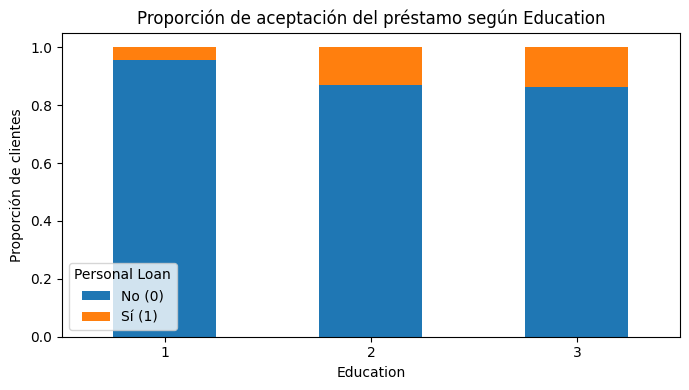

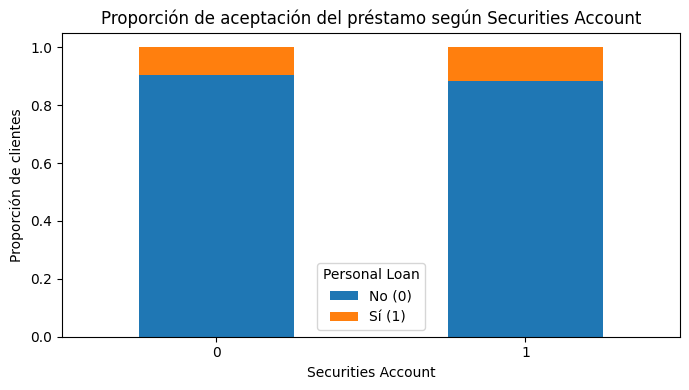

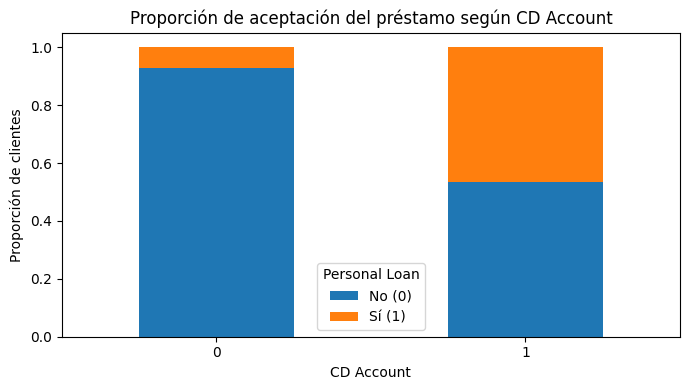

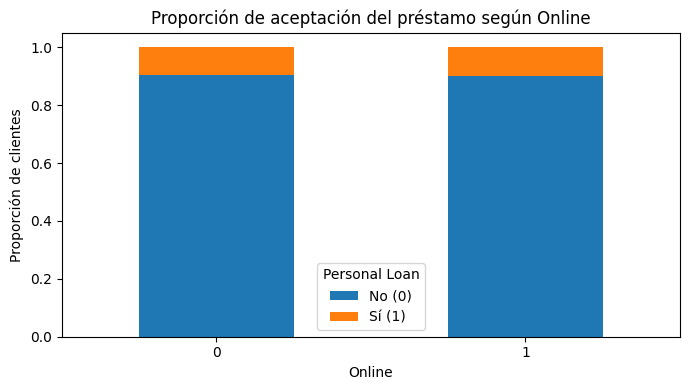

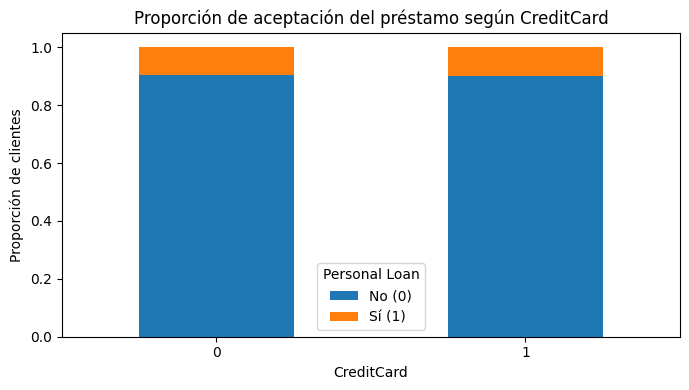

In [ ]:
# Seleccionar las variables categóricas, excluyendo ZIP Code y Personal Loan
cat_cols_loan = [
    columna for columna in cat_cols
    if columna not in ['ZIP Code', 'Personal Loan']
]

# Crear un gráfico de barras apiladas al 100 % para cada variable
for columna in cat_cols_loan:

    # Calcular la proporción de aceptación dentro de cada categoría
    proporciones = pd.crosstab(
        loan_df[columna],
        loan_df['Personal Loan'],
        normalize='index'
    )

    # Crear el gráfico de barras apiladas
    proporciones.plot(
        kind='bar',
        stacked=True,
        figsize=(7, 4)
    )

    plt.title(f'Proporción de aceptación del préstamo según {columna}')
    plt.xlabel(columna)
    plt.ylabel('Proporción de clientes')
    plt.legend(
        title='Personal Loan',
        labels=['No (0)', 'Sí (1)']
    )
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

**Hallazgos relevantes:**

1.   **El ingreso anual (Income)** es una de las variables que merece mayor atención, porque las diferencias entre las distribuciones de ambos grupos pueden indicar una asociación entre la capacidad económica y la aceptación del préstamo.
2.   La variable **CD Account** merece especial atención. Si la proporción de aceptación entre quienes tienen esta cuenta de certificado de depósito es considerablemente mayor, su posesión está asociada con una mayor tasa de aceptación del préstamo en estos datos. Sin embargo, eso no demuestra que tener esa cuenta cause la aceptación.

Google. (2026). Gemini (basado en Gemini 2.5) [Modelo de lenguaje grande], utilizado para la depuración y optimización del código. https://gemini.google.com/